First five rows:
  iso_code continent     location        date  total_cases  new_cases  \
0      AFG      Asia  Afghanistan  2020-02-24          5.0        5.0   
1      AFG      Asia  Afghanistan  2020-02-25          5.0        0.0   
2      AFG      Asia  Afghanistan  2020-02-26          5.0        0.0   
3      AFG      Asia  Afghanistan  2020-02-27          5.0        0.0   
4      AFG      Asia  Afghanistan  2020-02-28          5.0        0.0   

   new_cases_smoothed  total_deaths  new_deaths  new_deaths_smoothed  ...  \
0                 NaN           NaN         NaN                  NaN  ...   
1                 NaN           NaN         NaN                  NaN  ...   
2                 NaN           NaN         NaN                  NaN  ...   
3                 NaN           NaN         NaN                  NaN  ...   
4                 NaN           NaN         NaN                  NaN  ...   

   female_smokers  male_smokers  handwashing_facilities  \
0             NaN     

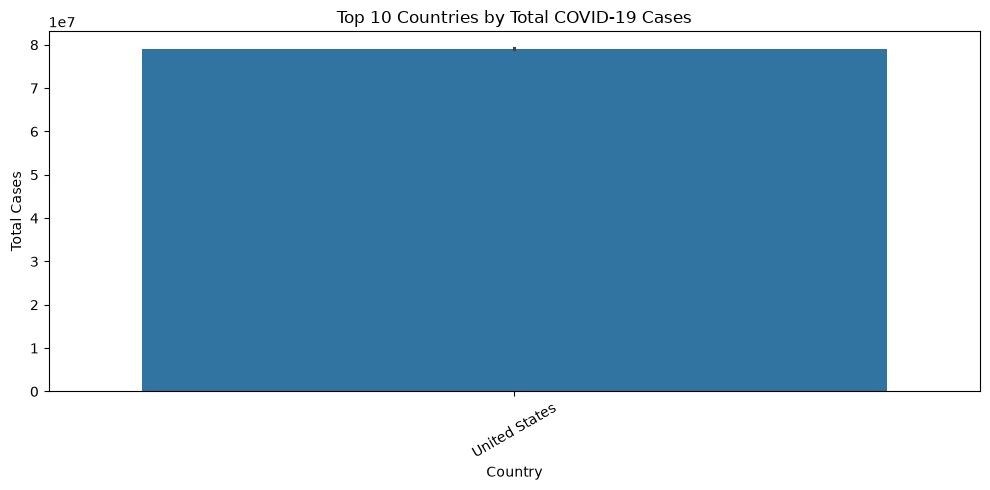

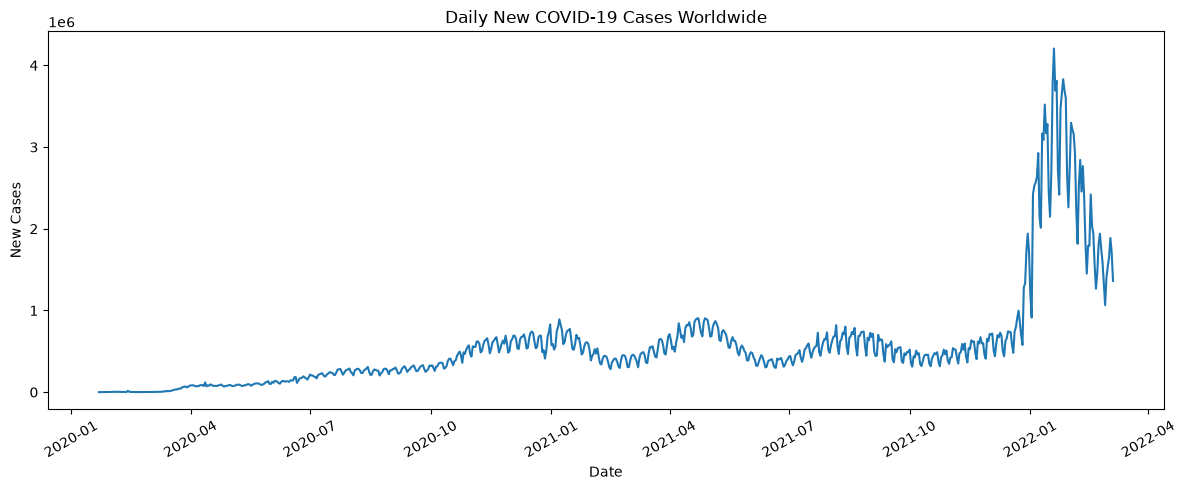

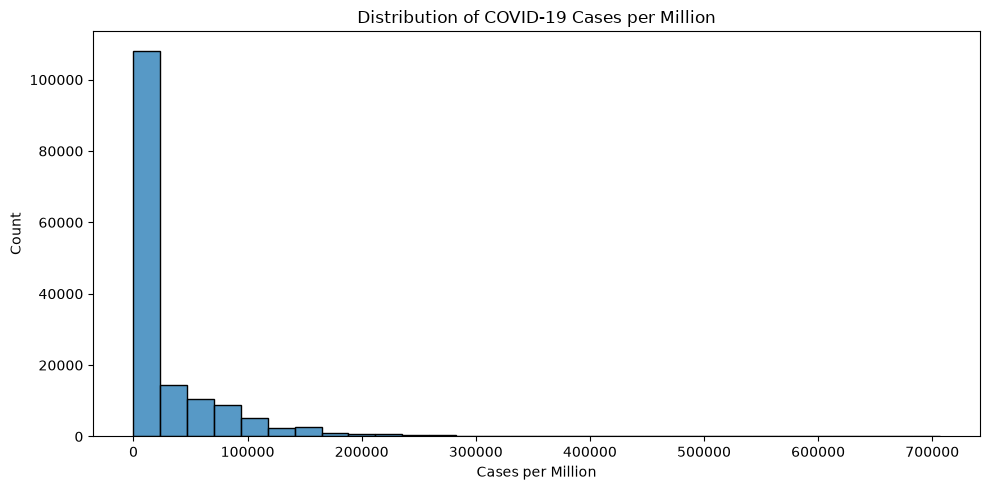

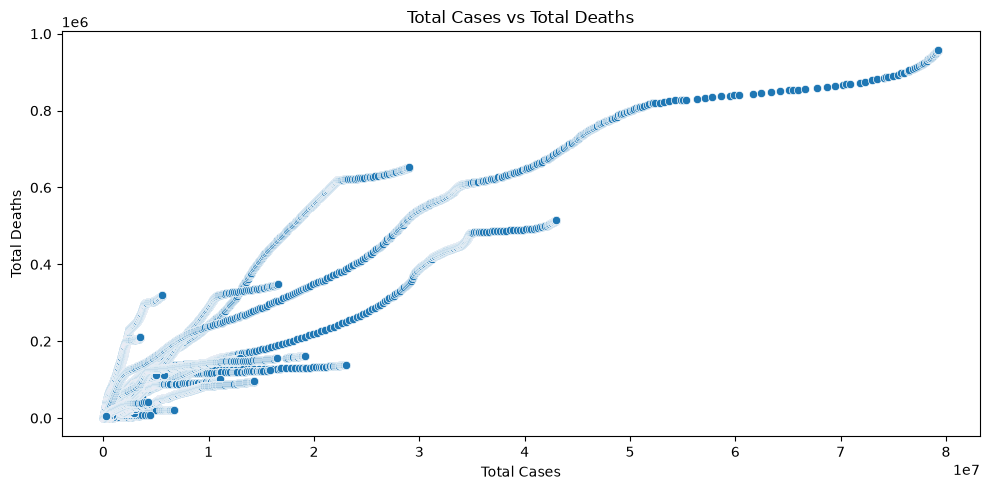

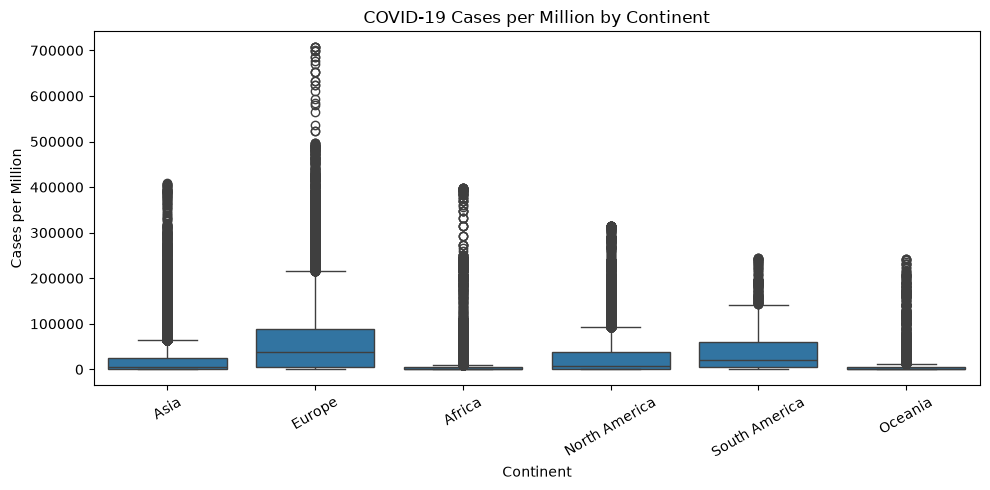

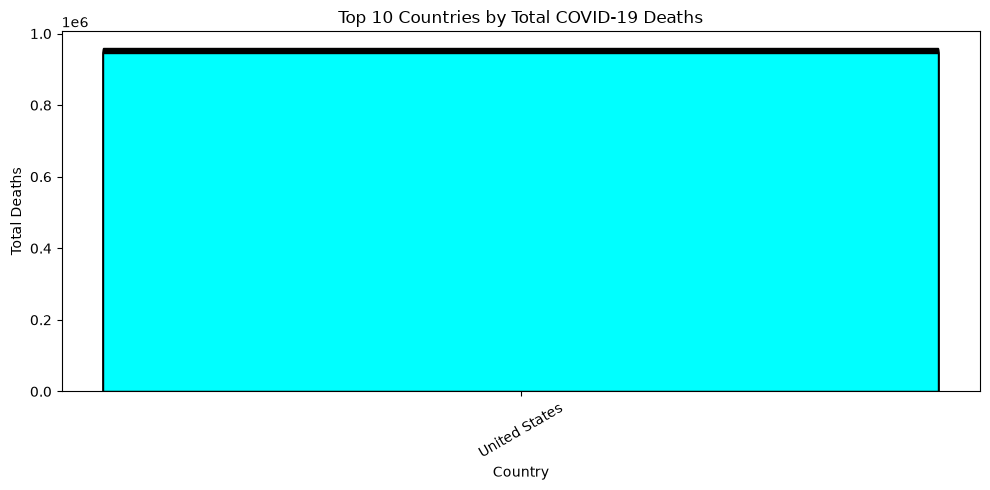

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the COVID-19 dataset
df = pd.read_csv("owid-covid-data.csv")

# View the data
print("First five rows:")
print(df.head())

print("Last five rows:")
print(df.tail())

print("Rows and columns:")
print(df.shape)

print("Column names:")
print(df.columns)

print("Dataset information:")
df.info()

print("Summary statistics:")
print(df.describe())

# Check missing values
print("Missing values in each column:")
print(df.isnull().sum())

print("Total missing values:")
print(df.isnull().sum().sum())

# Check duplicate rows
print("Duplicate rows:")
print(df.duplicated().sum())

# Clean the data
# Remove duplicate rows
df = df.drop_duplicates()

# Convert date values into datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Fill missing numerical values in selected columns with their median
columns_to_fill = [
    "total_cases",
    "total_deaths",
    "new_cases",
    "new_deaths",
    "total_cases_per_million"
]

for column in columns_to_fill:
    df[column] = df[column].fillna(df[column].median())

# Check missing values after cleaning
print("Missing values after cleaning:")
print(df.isnull().sum())

# Save the cleaned dataset
df.to_csv("owid-covid-data-cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

# Plot 1: Top 10 countries by total cases
# Use the World rows only once? No: select country rows by excluding World
country_data = df[df["continent"].notna()]

top_10 = country_data.sort_values(
    "total_cases", ascending=False
).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_10, x="location", y="total_cases")
plt.title("Top 10 Countries by Total COVID-19 Cases")
plt.xlabel("Country")
plt.ylabel("Total Cases")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Plot 2: Daily new cases worldwide
world_data = df[df["location"] == "World"]

plt.figure(figsize=(12, 5))
sns.lineplot(data=world_data, x="date", y="new_cases")
plt.title("Daily New COVID-19 Cases Worldwide")
plt.xlabel("Date")
plt.ylabel("New Cases")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Plot 3: Distribution of total cases per million
plt.figure(figsize=(10, 5))
sns.histplot(data=country_data, x="total_cases_per_million", bins=30)
plt.title("Distribution of COVID-19 Cases per Million")
plt.xlabel("Cases per Million")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Plot 4: Total cases versus total deaths
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=country_data,
    x="total_cases",
    y="total_deaths"
)
plt.title("Total Cases vs Total Deaths")
plt.xlabel("Total Cases")
plt.ylabel("Total Deaths")
plt.tight_layout()
plt.show()

# Plot 5: Compare cases per million across continents
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=country_data,
    x="continent",
    y="total_cases_per_million"
)
plt.title("COVID-19 Cases per Million by Continent")
plt.xlabel("Continent")
plt.ylabel("Cases per Million")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Plot 6: Top 10 countries by total deaths
top_deaths = country_data.sort_values(
    "total_deaths", ascending=False
).head(10)

plt.figure(figsize=(10, 5))
plt.bar(
    top_deaths["location"],
    top_deaths["total_deaths"],
    color="cyan",
    edgecolor="black"
)
plt.title("Top 10 Countries by Total COVID-19 Deaths")
plt.xlabel("Country")
plt.ylabel("Total Deaths")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


<Axes: xlabel='location', ylabel='total_cases'>

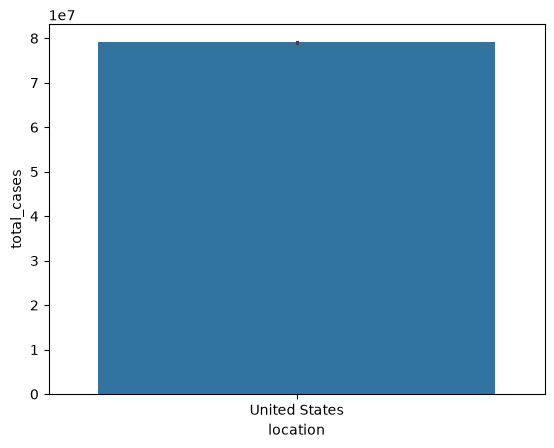

In [3]:
sns.barplot(data=top_10, x="location", y="total_cases")